# Homework Group 26 – Everything & Then Some

**Objective:** predict `repeat_purchase_90d` (binary classification) using `train.csv` (and, if useful, `clientes.csv`) and generate predictions for `test.csv`.

## 1. Import and explore the data

In this first section we only **look** at the data, without altering it. The steps are:

1. Load the files and understand their structure (columns, data types, variable groups)
2. Descriptive statistics
3. Distribution of the target variable
4. Missing values, duplicates and identifiers
5. Inconsistencies and anomalous values
6. Consistency of the categorical variables
7. Train vs. test (time periods and drift)
8. Univariate distributions
9. Relationships with the target (bivariate and multivariate)
10. The auxiliary `clientes.csv` table
11. Summary of the insights

### 1.1. Libraries and configuration

In [2]:
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Random seed: guarantees that later results are reproducible
SEED = 42
np.random.seed(SEED)

# Name of the column we want to predict (stored once to avoid typos)
TARGET = "repeat_purchase_90d"

### 1.2. Loading the datasets

Four datasets were provided:
- `train.csv`: historical purchase occasions with the target (what the model learns from).
- `test.csv`: later purchase occasions without the target, for which we must generate predictions.
- `clientes.csv`: optional customer-level table, linked through `customer_id`.
- `sample_submission.csv`: required submission format (`ID`, `repeat_purchase_90d`).

In [10]:
train = pd.read_csv("hdata/train.csv")
test = pd.read_csv("hdata/test.csv")
clientes = pd.read_csv("hdata/clientes.csv")
sample_submission = pd.read_csv("hdata/sample_submission.csv")

# Dataset dimensions (rows, columns)
print("train            :", train.shape)
print("test             :", test.shape)
print("clientes         :", clientes.shape)
print("sample_submission:", sample_submission.shape)

train            : (6534, 39)
test             : (986, 38)
clientes         : (1143, 13)
sample_submission: (986, 2)


In [11]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [12]:
clientes.head()

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


**What we see:** the training set has 39 columns and the test set 38. The missing column should be the target, since it is absent from the test set. Let's confirm this.

### 1.3. Table structure and variable types

First we confirm that train and test have the same columns, except for the target. This matters: if a column were missing from the test set, the model could not use it.

In [13]:
cols_only_train = set(train.columns) - set(test.columns)
cols_only_test = set(test.columns) - set(train.columns)

print("Columns only in train:", cols_only_train)
print("Columns only in test :", cols_only_test)

Columns only in train: {'repeat_purchase_90d'}
Columns only in test : set()


Now, we examine the data types of the variables to distinguish between numerical, categorical and date-related attributes and identify potencial inconsistencies.

In [14]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

Next we group the columns by type of information. This does not change the data, it only organises our line of thought and gives us lists to reuse later.

In [15]:
# Numerical columns (current purchase values and customer history)
num_cols = train.select_dtypes(include="number").columns.difference([TARGET, "ID", "customer_id"]).tolist()

# Text columns (categories)
CATEGORICAL = ["payment_type", "salesperson", "commercial_zone",
               "transport_method", "warehouse", "document_series"]

# Special columns that we do not treat as standard variables
id_cols = ["ID", "customer_id"]       # identifiers
date_col = "purchase_date"            # date (currently stored as text)
noise_col = "random_noise"            # the name suggests pure noise; checked later

# 'random_noise' is numeric, so it appeared in num_cols; we keep it separate
num_cols = [c for c in num_cols if c != noise_col]

print(f"{len(num_cols)} numerical | {len(CATEGORICAL)} categorical | {len(id_cols)} identifiers | 1 date | 1 noise")
print("\nNumerical:", num_cols)

28 numerical | 6 categorical | 2 identifiers | 1 date | 1 noise

Numerical: ['Custo', 'N_ Detalhes', 'Total Bruto', 'Total Desc_ Global', 'Total Desc_ Linha', 'Total Imp_', 'Total Liquido', 'Total Portes', 'Total a Pagar', 'customer_tenure_days', 'days_since_previous_purchase', 'invoice_count_current_purchase', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_mean_purchase_value', 'prior_min_purchase_value', 'prior_purchase_count', 'prior_std_gap_days', 'prior_std_purchase_value', 'prior_total_spend', 'purchase_count_180d', 'purchase_count_30d', 'purchase_count_365d', 'purchase_count_90d', 'spend_180d', 'spend_30d', 'spend_365d', 'spend_90d']


We also check the number of distinct values of each categorical column (its cardinality). This determines how we will convert them into numbers later on: a column with 2 categories is straightforward, whereas one with 80 requires more effort.

In [16]:
print(train[CATEGORICAL].nunique().sort_values(ascending=False))

transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2
dtype: int64


**What we see:** `transport_method` has about 80 categories, far more than the others. If we were to create a separate column for each category, we would end up with 80 columns for this variable alon. We'll keep this in mind for the preprocessing stage.

### 1.4. Descriptive statistics

The descriptive statistics of the numerical variables show the average values, the spread of the data and any unusual values that need further investigation.

In [17]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,9.300000e-01,1.889200e+02,4.767400e+02,1.087670e+03,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,8.300000e-01,1.757400e+02,4.457400e+02,1.036700e+03,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,7.600000e-01,1.543800e+02,3.899100e+02,9.033700e+02,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000e+00,2.993000e+01,7.974000e+01,1.848400e+02,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000e+00,0.000000e+00,1.313000e+01,9.228000e+01,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000e+00,4.905000e+01,1.525400e+02,3.960615e+02,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000e+00,4.000000e+00,1.100000e+01,2.900000e+01,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00


**Observations from `describe()`:**
- `prior_mean_purchase_value` and `spend_365d` reach **1,000,000,000** and also take **negative values**, which is impossible for a purchase value/spend. These look like sentinel or corrupted codes, not real outliers.
- `days_since_previous_purchase` and `prior_mean_gap_days` have a **negative minimum**, which is impossible for a time interval.
- `Total Desc_ Global` and `Total Portes` are almost always 0.
- `prior_purchase_count` reaches 276: high, but plausible for very frequent customers.
- Most monetary variables have a mean much larger than the median.

### 1.5. The target: `repeat_purchase_90d`

The target is 1 if the customer made another purchase within the following 90 days, and 0 otherwise. We need to determine whether the classes are balanced, as this influences the choice of metric (in the case of highly imbalanced classes, accuracy can be misleading).

                        n  proportion
repeat_purchase_90d                  
0                    2880       0.441
1                    3654       0.559


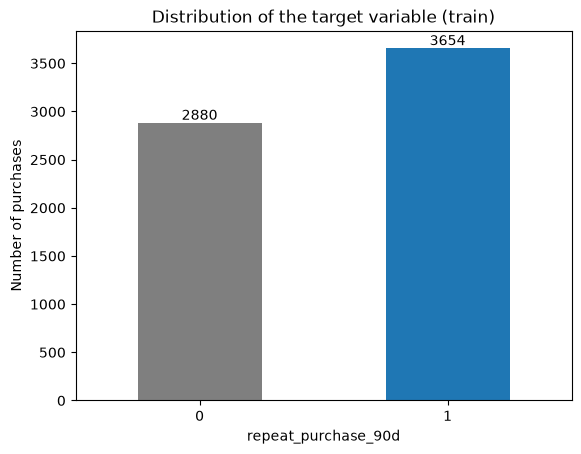

In [19]:
count = train[TARGET].value_counts().sort_index()
proportion = train[TARGET].value_counts(normalize=True).sort_index().round(3)

print(pd.DataFrame({"n": count, "proportion": proportion}))

# bar chat to visualize the distribution of the target variable
ax = count.plot(kind="bar", color=["tab:gray", "tab:blue"], rot=0)
ax.set_title("Distribution of the target variable (train)")
ax.set_xlabel(TARGET)
ax.set_ylabel("Number of purchases")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

**What we see:** approximately 56% of 1s and 44% of 0s. The classes are reasonably balanced, so we don't need any speacil balancing techniques.

### 1.6. Missing values, duplicates and identifiers

A missing value (`NaN`) can arise for very different reasons:
- **error / empty row:** the record is incomplete;
- **structural absence:** the value does not exist by definition (e.g. a customer making their first purchase cannot have a "standard deviation of previous purchases").

Treating both cases the same way would be a mistake, so we first **measure** them.

#### 1.6.1. Missing values by variable (train and test)

In [20]:
def missing_table(df):
    # Number and % of missing values by column, only for columns that have any
    n = df.isna().sum()
    pct = (df.isna().mean() * 100).round(1)
    out = pd.DataFrame({"n_missing": n, "%": pct})
    return out[out["n_missing"] > 0].sort_values("n_missing", ascending=False)

missing_train = missing_table(train)
print("=== TRAIN ===")
print(missing_train)
print("\n=== TEST ===")
print(missing_table(test))

=== TRAIN ===
                                n_missing     %
prior_std_gap_days                   1478  22.6
prior_mean_gap_days                  1308  20.0
prior_std_purchase_value             1113  17.0
prior_mean_purchase_value             862  13.2
days_since_previous_purchase          861  13.2
prior_max_purchase_value              668  10.2
prior_min_purchase_value              668  10.2
transport_method                      261   4.0
warehouse                             260   4.0
payment_type                          260   4.0
spend_365d                            260   4.0
salesperson                           259   4.0
Total Imp_                             65   1.0
Total Liquido                          65   1.0
Total Bruto                            65   1.0
Total a Pagar                          65   1.0
customer_tenure_days                   65   1.0
invoice_count_current_purchase         65   1.0
N_ Detalhes                            65   1.0
Total Portes              

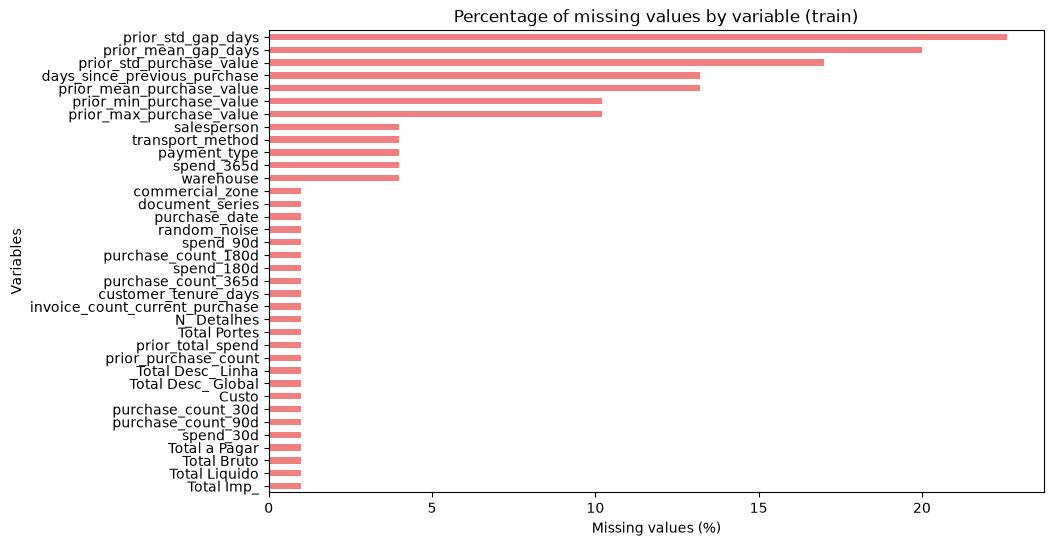

In [22]:
plt.figure(figsize=(10, 6))

missing_train["%"].sort_values().plot(kind="barh", color="lightcoral")
plt.title("Percentage of missing values by variable (train)")
plt.xlabel("Missing values (%)")
plt.ylabel("Variables")
plt.show()

**What we see:** in the training set, many columns have exactly **65** missing values. This recurring number is suspicious: it suggests that the **same 65 rows** are empty everywhere. Let's verify.

#### 1.6.2. Missing values per observation

We also check how missing values are distrivuted across observations to identify whether some rows have significantly more missing information than others. This is important because some purchases might have almost no informations available. We need to identify these observations before deiciding whether to keep, fix or remove them.

In [23]:
# Columns that are neither identifiers nor the target
feature_columns = [c for c in train.columns if c not in [TARGET, "ID", "customer_id"]]

# For each row, how many of these columns are missing?
missing_per_row = train[feature_columns].isna().sum(axis=1)

print("Number of missing columns per row (rows with at least one missing value):")
print(missing_per_row[missing_per_row > 0].value_counts().sort_index())

Number of missing columns per row (rows with at least one missing value):
1     1287
2      190
3      354
4      100
5        6
7      511
8       86
9        6
36      65
Name: count, dtype: int64


In [24]:
# Rows where every feature is missing
empty_rows_train = train[feature_columns].isna().all(axis=1)
print("Rows with every feature missing:", empty_rows_train.sum())
print("Target in those rows:", train.loc[empty_rows_train, TARGET].value_counts().to_dict())

train.loc[empty_rows_train, ["ID", "customer_id", TARGET, date_col, "Total a Pagar", "payment_type"]].head()

Rows with every feature missing: 65
Target in those rows: {1: 33, 0: 32}


,ID,customer_id,repeat_purchase_90d,purchase_date,Total a Pagar,payment_type
393,10000457,755628,1,NaN,NaN,NaN
484,10000560,755628,1,NaN,NaN,NaN
582,10000678,427118,1,NaN,NaN,NaN
583,10000679,508217,0,NaN,NaN,NaN
748,10000870,427118,0,NaN,NaN,NaN


**What we see:** **65 training rows are empty** (only `ID`, `customer_id` and the target are filled in) and the target is split 33/32 in them. Without any other variable these rows carry no information, and the test set contains no such rows.

Next, we look at the missing values that remain once these empty rows are set aside, the ones that occur within the "valid" data.

In [25]:
train_ok = train.loc[~empty_rows_train]

print("Train without empty rows:", train_ok.shape, "\n")
print(missing_table(train_ok))

Train without empty rows: (6469, 39) 

                              n_missing     %
prior_std_gap_days                 1413  21.8
prior_mean_gap_days                1243  19.2
prior_std_purchase_value           1048  16.2
prior_mean_purchase_value           797  12.3
days_since_previous_purchase        796  12.3
prior_min_purchase_value            603   9.3
prior_max_purchase_value            603   9.3
transport_method                    196   3.0
spend_365d                          195   3.0
payment_type                        195   3.0
warehouse                           195   3.0
salesperson                         194   3.0


#### 1.6.3. Missing values and previous purchases (structural missingness)

The `prior_std_gap_days`, `prior_mean_gap_days`, `prior_std_purchase_value` columns describe the customer's history. Our hypothesis is that they are missing when the customer has **few prior purchases** to compute them. We first look at `prior_std_purchase_value` by number of previous purchases.

In [26]:
train.groupby("prior_purchase_count")["prior_std_purchase_value"].apply(
    lambda x: x.isnull().mean() * 100
).head(10)

prior_purchase_count
0.0    100.0
1.0    100.0
2.0      0.0
3.0      0.0
4.0      0.0
5.0      0.0
6.0      0.0
7.0      0.0
8.0      0.0
9.0      0.0
Name: prior_std_purchase_value, dtype: float64

- 0 previous purchases → 100% missing: there is no purchase history to compute a standard deviation.
- 1 previous purchase → 100% missing: one purchase is not enough to compute a sample standard deviation.
- 2 or more previous purchases → 0% missing: there is enough information.

We extend the test to all history columns: what share of their missing values occurs for customers with 0 or 1 previous purchases?

In [27]:
prior_cols = ["prior_min_purchase_value", "prior_std_purchase_value", "prior_std_gap_days",
              "prior_mean_gap_days", "prior_mean_purchase_value", "days_since_previous_purchase"]

rows = []
for c in prior_cols:
    is_missing = train_ok[c].isna()
    few_purchases = train_ok.loc[is_missing, "prior_purchase_count"] <= 1
    rows.append({"column": c,
                 "n_missing": int(is_missing.sum()),
                 "% with 0 or 1 previous purchases": round(few_purchases.mean() * 100, 1)})

print(pd.DataFrame(rows).to_string(index=False))
print("\nFirst purchases (prior_purchase_count == 0):", (train["prior_purchase_count"] == 0).sum())

                      column  n_missing  % with 0 or 1 previous purchases
    prior_min_purchase_value        603                             100.0
    prior_std_purchase_value       1048                             100.0
          prior_std_gap_days       1413                              74.2
         prior_mean_gap_days       1243                              84.3
   prior_mean_purchase_value        797                              78.2
days_since_previous_purchase        796                              78.1

First purchases (prior_purchase_count == 0): 603


**What we see:** the hypothesis is partly confirmed.
- `prior_min_purchase_value` and `prior_std_purchase_value` are only missing when the customer has 0 or 1 previous purchases: a **structural** absence (603 rows are first purchases).
- For the remaining columns, most missing values (≈75–85%) also come from customers with few previous purchases, but some do **not**: customers with many previous purchases (even over 200) still lack `days_since_previous_purchase` or a mean. These have a different origin (partly the impossible values we detect in 1.7).

**Conclusion:** most of the missingness is informative – it tells us the customer has little or no purchase history.

#### 1.6.4. Duplicates and identifiers

In [28]:
print("Duplicated training rows:", train.duplicated().sum())
print("Duplicated training IDs:", train["ID"].duplicated().sum())
print("Duplicated rows ignoring ID:", train.drop(columns="ID").duplicated().sum())

print("\nUnique customers in train:", train["customer_id"].nunique())
print("Unique customers in test:", test["customer_id"].nunique())

Duplicated training rows: 0
Duplicated training IDs: 0
Duplicated rows ignoring ID: 10

Unique customers in train: 610
Unique customers in test: 206


**What we see:** there are no duplicated rows or repeated `ID`s; each `ID` is a unique purchase observation. The 10 rows that are duplicated when `ID` is ignored are the empty rows of the same customers (only `customer_id` and target filled). About 610 customers generate 6,534 purchases, so **the same customer appears many times**.

### 1.7. Data inconsistencies and anomalous values

We now look for values that are impossible or unrealistic, such as negative time intervals or extremely large amounts.
This helps us identify possible data quality issues taht may need to be addressed during preprocessing.

#### 1.7.1. Minimum and maximum values

In [30]:
train.select_dtypes(include="number").agg(["min", "max"]).T.round(2)

,min,max
Total a Pagar,0.93,2.229721e+04
Total Bruto,0.83,2.157828e+04
Total Liquido,0.76,1.812781e+04
Total Imp_,0.00,4.169400e+03
Total Portes,0.00,1.810600e+02
Total Desc_ Global,0.00,2.184900e+02
Total Desc_ Linha,0.00,4.103440e+03
Custo,0.00,7.427400e+03
N_ Detalhes,1.00,4.230000e+02
invoice_count_current_purchase,1.00,5.000000e+00


The minimum and maximum values reveal suspicious observations:
- **Negative time intervals:** `days_since_previous_purchase` and `prior_mean_gap_days` have a minimum of -4, but the time between purchases cannot be negative.
- **Negative monetary values:** `prior_mean_purchase_value` (-2,478.66) and `spend_365d` (-159,115.20) – errors, refunds or accounting adjustments.
- **Extremely large values:** `prior_mean_purchase_value` and `spend_365d` reach 1,000,000,000, unrealistic compared with typical purchase amounts.

#### 1.7.2. Negative values

In [31]:
variables = ["days_since_previous_purchase", "prior_mean_gap_days",
             "prior_mean_purchase_value", "spend_365d"]
(train[variables] < 0).sum()

days_since_previous_purchase    16
prior_mean_gap_days             16
prior_mean_purchase_value       16
spend_365d                      15
dtype: int64

We found a small number of negative values in four variables. These values seem unusual, especially for the time between purchases, and may indicate data errors.

#### 1.7.3. Extremely large values

In [32]:
print("Rows with a value >= 1e8:")
print((train[["prior_mean_purchase_value", "spend_365d"]] >= 1e8).sum())

train[["prior_mean_purchase_value", "spend_365d"]].sort_values(by="spend_365d", ascending=False).head(10)

Rows with a value >= 1e8:
prior_mean_purchase_value    16
spend_365d                   15
dtype: int64


,prior_mean_purchase_value,spend_365d
3514,615.926667,1.000000e+09
2356,870.590000,1.000000e+09
2369,2114.369286,1.000000e+09
4155,1196.175094,1.000000e+09
4395,977.420000,1.000000e+09
1630,NaN,1.000000e+09
3324,154.767826,1.000000e+09
1029,902.712018,1.000000e+09
5851,1801.632857,1.000000e+09
2590,828.988529,1.000000e+09


**What we see:** only around 15–16 rows per variable are negative, and some customers have `spend_365d` value of 1, billion even though their average previous purchase is a few hundred. These are not real outliers but **sentinel/corrupted codes**.

### 1.8. Consistency of categorical variables

Text categories may be written inconsistently (accents, upper/lower case, extra spaces). We normalise them and check whether the number of levels changes. We also count how many test rows use a level that never appears in training, since the model cannot learn anything about those.

In [33]:
def normalize_string_columns(df: pd.DataFrame) -> pd.DataFrame:
    # Remove accents and extra spaces and convert all text columns to lowercase
    df_clean = df.copy()
    df_clean.columns = df_clean.columns.str.strip().str.lower()
    text_columns = df_clean.select_dtypes(include=["object", "string"]).columns

    for col in text_columns:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()
        df_clean[col] = df_clean[col].apply(
            lambda x: "".join(c for c in unicodedata.normalize("NFD", x)
                              if unicodedata.category(c) != "Mn") if pd.notna(x) else x
        )
        df_clean[col] = df_clean[col].replace("nan", pd.NA)

    return df_clean


train_normalized = normalize_string_columns(train)
pd.DataFrame({
    "levels_original": train[CATEGORICAL].nunique(),
    "levels_normalized": train_normalized[CATEGORICAL].nunique(),
    "test_rows_with_unseen_level": [(~test[c].dropna().isin(train[c].dropna())).sum() for c in CATEGORICAL],
})

,levels_original,levels_normalized,test_rows_with_unseen_level
payment_type,9,9,3
salesperson,9,9,0
commercial_zone,5,5,209
transport_method,80,80,63
warehouse,2,2,7
document_series,3,3,0


**What we see:**
- Normalisation does not change the number of levels, so the categories are written consistently.
- Several test rows use levels never seen in training (e.g. 209 for `commercial_zone`, 63 for `transport_method`).

### 1.9. Train vs. test: time periods and drift

The `purchase_date` column is stored as text. We convert it to a date to compare when the training and test purchases happen.

In [34]:
# errors="coerce": invalid dates become NaT instead of raising an error
train_dates = pd.to_datetime(train[date_col], errors="coerce")
test_dates = pd.to_datetime(test[date_col], errors="coerce")

print("Train period:", train_dates.min().date(), "to", train_dates.max().date())
print("Test period :", test_dates.min().date(), "to", test_dates.max().date())

# Number of purchases per year, train vs test
print(pd.DataFrame({"train": train_dates.dt.year.value_counts().sort_index(),
                    "test": test_dates.dt.year.value_counts().sort_index()}).fillna(0).astype(int))

Train period: 2015-07-11 to 2025-02-15
Test period : 2025-05-24 to 2026-10-06
               train  test
purchase_date             
2015.0           335     0
2016.0           420     0
2017.0           670     0
2018.0           716     0
2019.0           646     0
2020.0           670     0
2021.0           782     0
2022.0           628     0
2023.0           767     0
2024.0           757     0
2025.0            78   465
2026.0             0   521


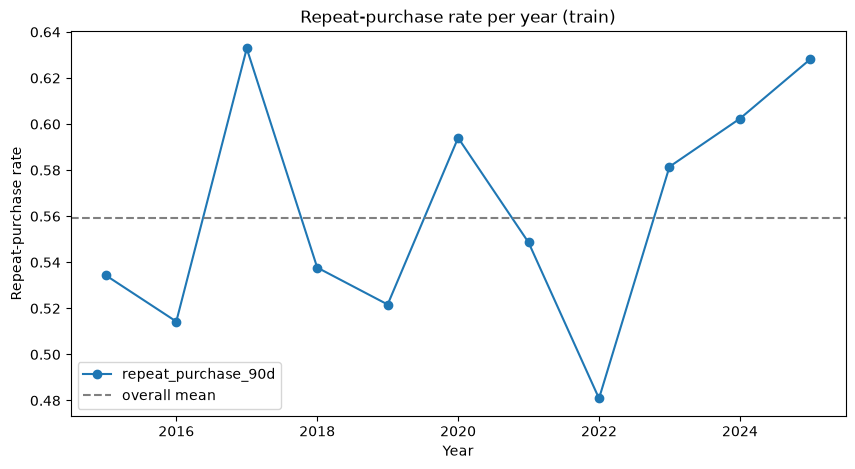

,train_median,test_median
customer_tenure_days,918.00,2662.00
prior_purchase_count,11.00,28.00
prior_total_spend,6754.31,25186.53
purchase_count_365d,3.00,4.00
days_since_previous_purchase,57.00,59.00


In [35]:
# Repeat-purchase rate per year (train only)
yearly_rate = train.groupby(train_dates.dt.year)[TARGET].mean()

ax = yearly_rate.plot(marker="o", figsize=(10, 5))
ax.axhline(train[TARGET].mean(), color="gray", linestyle="--", label="overall mean")
ax.set(title="Repeat-purchase rate per year (train)", xlabel="Year", ylabel="Repeat-purchase rate")
ax.legend()
plt.show()

# Do customers look the same in train and test?
pd.DataFrame({"train_median": train.median(numeric_only=True),
              "test_median": test.median(numeric_only=True)}).loc[
    ["customer_tenure_days", "prior_purchase_count", "prior_total_spend",
     "purchase_count_365d", "days_since_previous_purchase"]]

**What we see:**
- Training purchases go from July 2015 to February 2025 and test purchases from May 2025 to October 2026: **the test set lies in the future** relative to the training set.
- The repeat-purchase rate varies over the years (≈48%–63%) with no clear trend.
- Test customers have about **2.5–3× more tenure, prior purchases and prior spend** than training customers, simply because time has passed (cumulative variables grow). Rates and recent-window counts (`purchase_count_365d`, `days_since_previous_purchase`) are much more stable.

### 1.10. Univariate distributions

We explore the distributions of some numerical and categorical variables with histograms, boxplots and countplots, to understand purchasing behaviour and identify outliers.

#### 1.10.1. Purchase amount

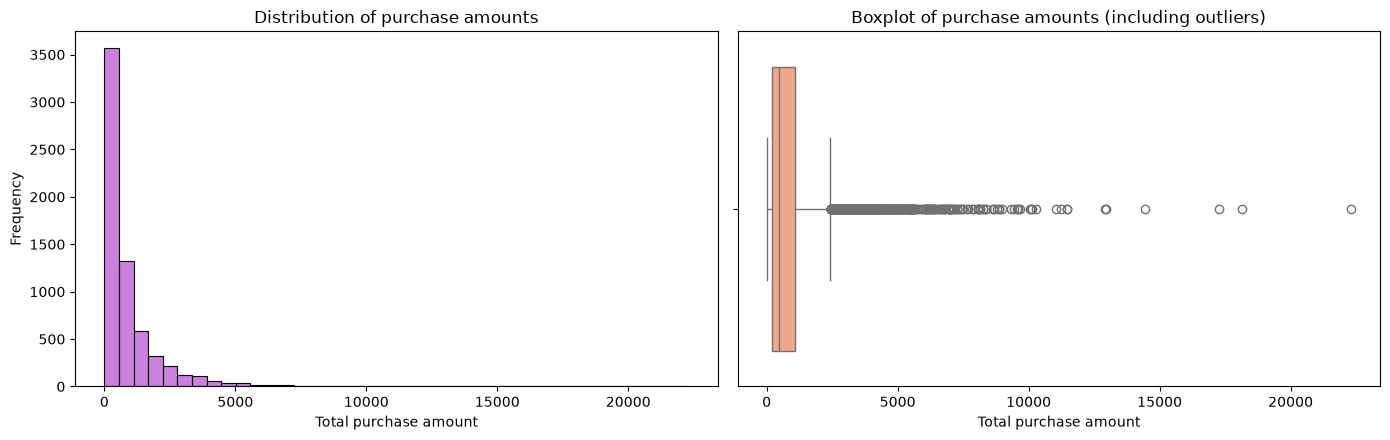

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=train, x="Total a Pagar", bins=40, color="mediumorchid", ax=axes[0])
axes[0].set(title="Distribution of purchase amounts", xlabel="Total purchase amount", ylabel="Frequency")

sns.boxplot(data=train, x="Total a Pagar", color="lightsalmon", ax=axes[1])
axes[1].set(title="Boxplot of purchase amounts (including outliers)", xlabel="Total purchase amount")

plt.tight_layout()
plt.show()

Most purchases have relatively low amounts, while a few are much larger (some above 20,000), producing a strongly **right-skewed** distribution with many outliers.

#### 1.10.2. Number of previous purchases

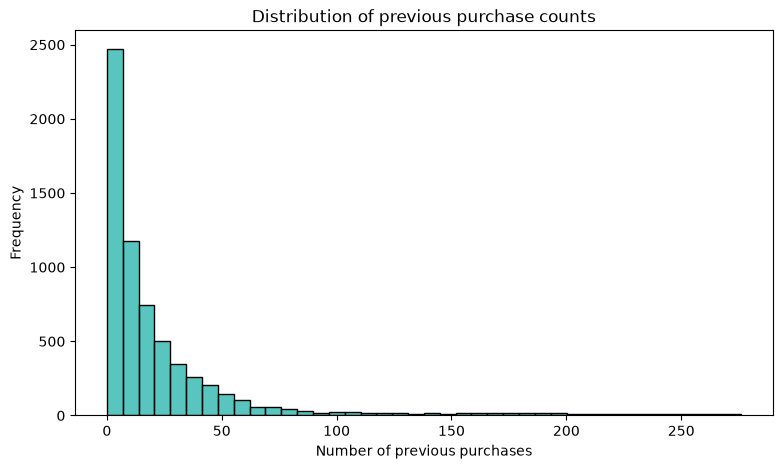

In [37]:
plt.figure(figsize=(9, 5))
sns.histplot(data=train, x="prior_purchase_count", bins=40, color="lightseagreen")
plt.title("Distribution of previous purchase counts")
plt.xlabel("Number of previous purchases")
plt.ylabel("Frequency")
plt.show()

Most observations belong to customers with relatively few previous purchases, while a smaller number have a long purchasing history. Purchasing frequency varies considerably between customers, which could be an important predictor.

#### 1.10.3. Payment types

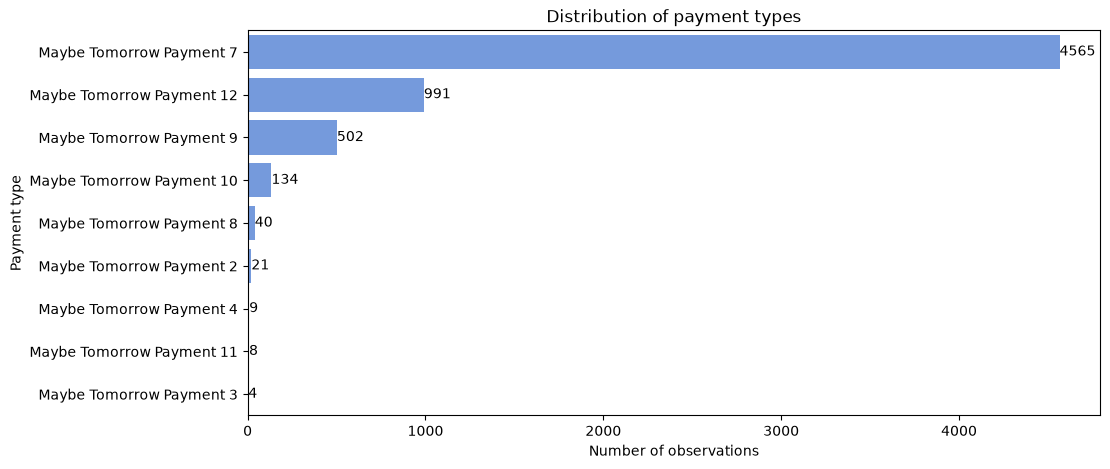

In [38]:
plt.figure(figsize=(11, 5))
ax = sns.countplot(data=train, y="payment_type",
                   order=train["payment_type"].value_counts().index, color="cornflowerblue")
plt.title("Distribution of payment types")
plt.xlabel("Number of observations")
plt.ylabel("Payment type")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

Payment Type 7 is by far the most common, followed by Payment Types 12 and 9. The remaining categories are rare, so payment types are far from equally distributed.

### 1.11. Relationships with the target

We now explore how the variables relate to `repeat_purchase_90d`, to identify patterns that may help predict whether a customer purchases again within 90 days.

#### 1.11.1. Numerical variables vs. target

Median prior_purchase_count by class:
repeat_purchase_90d
0     6.0
1    17.0
Name: prior_purchase_count, dtype: float64


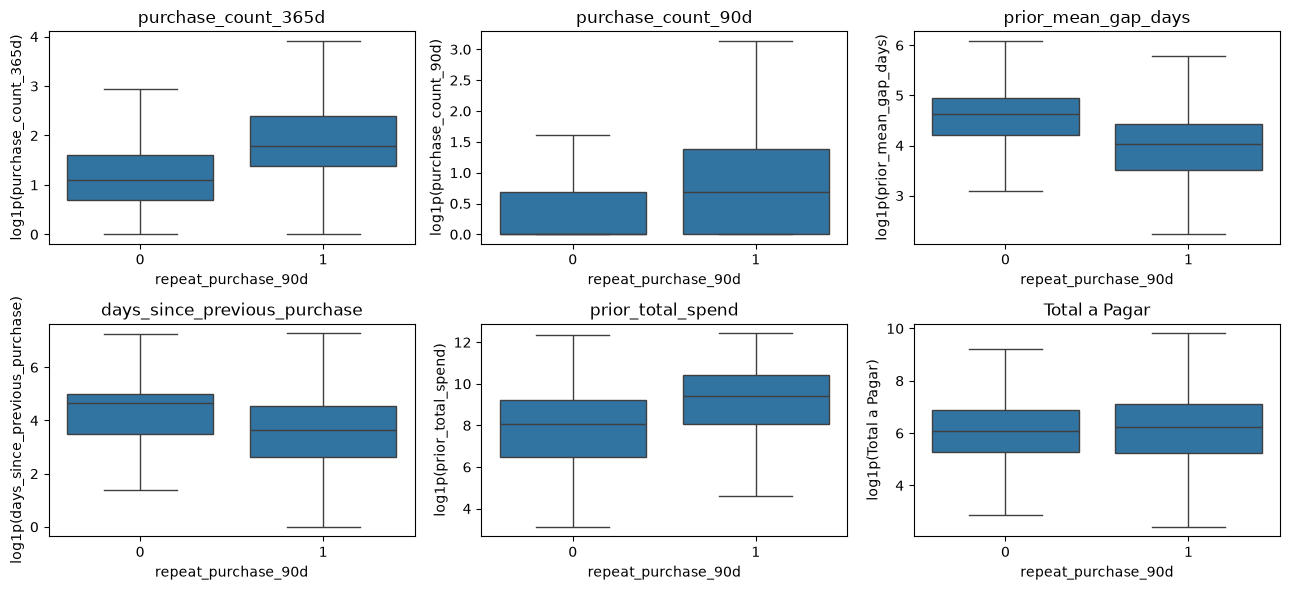

In [39]:
print("Median prior_purchase_count by class:")
print(train.groupby(TARGET)["prior_purchase_count"].median())

key_numeric = ["purchase_count_365d", "purchase_count_90d", "prior_mean_gap_days",
               "days_since_previous_purchase", "prior_total_spend", "Total a Pagar"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), key_numeric):
    # clip and log1p are applied only for this plot, to make the skewed values readable
    sns.boxplot(data=train, x=TARGET, y=np.log1p(train[col].clip(lower=0, upper=1e7)), ax=ax, showfliers=False)
    ax.set(title=col, ylabel=f"log1p({col})")
plt.tight_layout()
plt.show()

**What we see:**
- Customers who purchase again within 90 days have many more previous purchases (median 17 vs. 6).
- Customers who **buy often** (high `purchase_count_*`) and have **short historical gaps** (low `prior_mean_gap_days`, `days_since_previous_purchase`) are much more likely to buy again: **frequency and recency are the main signal**.
- The value of the current purchase (`Total a Pagar`) hardly separates the classes.

#### 1.11.2. Categorical variables vs. target

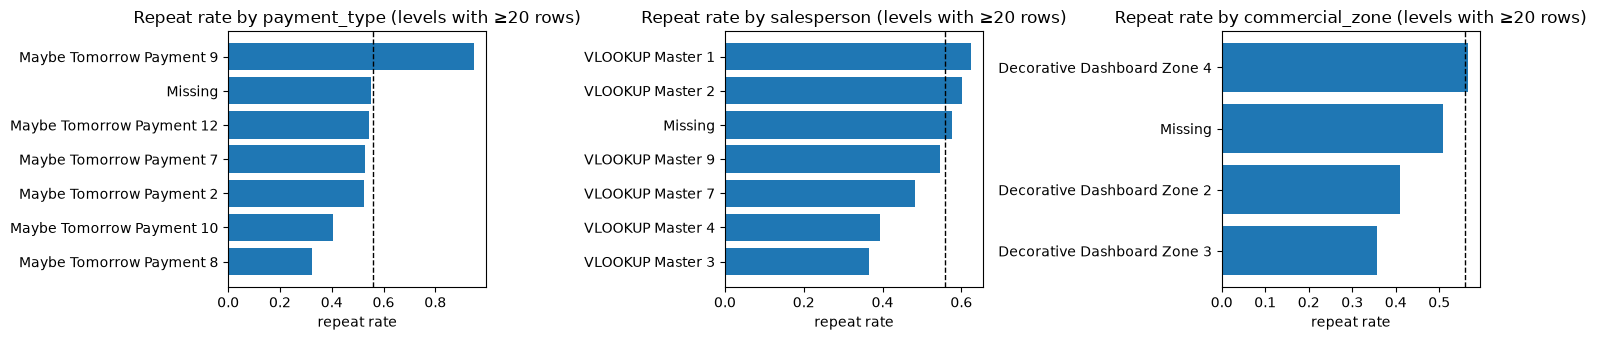

,repeat_rate_pct,n
payment_type,,
Maybe Tomorrow Payment 9,95.0,502
Maybe Tomorrow Payment 11,62.5,8
Missing,55.0,260
Maybe Tomorrow Payment 12,54.3,991
Maybe Tomorrow Payment 7,52.7,4565
Maybe Tomorrow Payment 2,52.4,21
Maybe Tomorrow Payment 3,50.0,4
Maybe Tomorrow Payment 4,44.4,9
Maybe Tomorrow Payment 10,40.3,134


In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["payment_type", "salesperson", "commercial_zone"]):
    rate = train.groupby(train[col].fillna("Missing"))[TARGET].agg(["mean", "size"])
    rate = rate[rate["size"] >= 20].sort_values("mean")
    ax.barh(rate.index, rate["mean"])
    ax.axvline(train[TARGET].mean(), color="black", ls="--", lw=1)
    ax.set(title=f"Repeat rate by {col} (levels with ≥20 rows)", xlabel="repeat rate")
plt.tight_layout()
plt.show()

# Exact repeat rate (%) and size of each payment type
train.groupby(train["payment_type"].fillna("Missing"))[TARGET].agg(
    repeat_rate_pct=lambda s: round(s.mean() * 100, 1), n="size"
).sort_values("repeat_rate_pct", ascending=False)

**What we see:** repeat rates vary strongly between categories. `payment_type` *Maybe Tomorrow Payment 9* has a ≈95% repeat rate (≈500 rows), while Payment 8 has only ≈32% and `salesperson` *VLOOKUP Master 2* ≈39%. These categorical variables carry real information. However, some categories have few observations, so their rates must be interpreted carefully.

#### 1.11.3. Correlations (Spearman)

We use **Spearman** correlation because it is based on ranks and is therefore robust to the skewness and extreme values identified above.

purchase_count_365d             0.437
purchase_count_180d             0.406
purchase_count_90d              0.393
spend_365d                      0.386
spend_90d                       0.359
prior_purchase_count            0.346
prior_total_spend               0.332
purchase_count_30d              0.261
Total Imp_                      0.081
Total Bruto                     0.078
Total a Pagar                   0.053
Total Liquido                   0.050
random_noise                   -0.008
Custo                          -0.013
days_since_previous_purchase   -0.311
prior_mean_gap_days            -0.417
Name: repeat_purchase_90d, dtype: float64


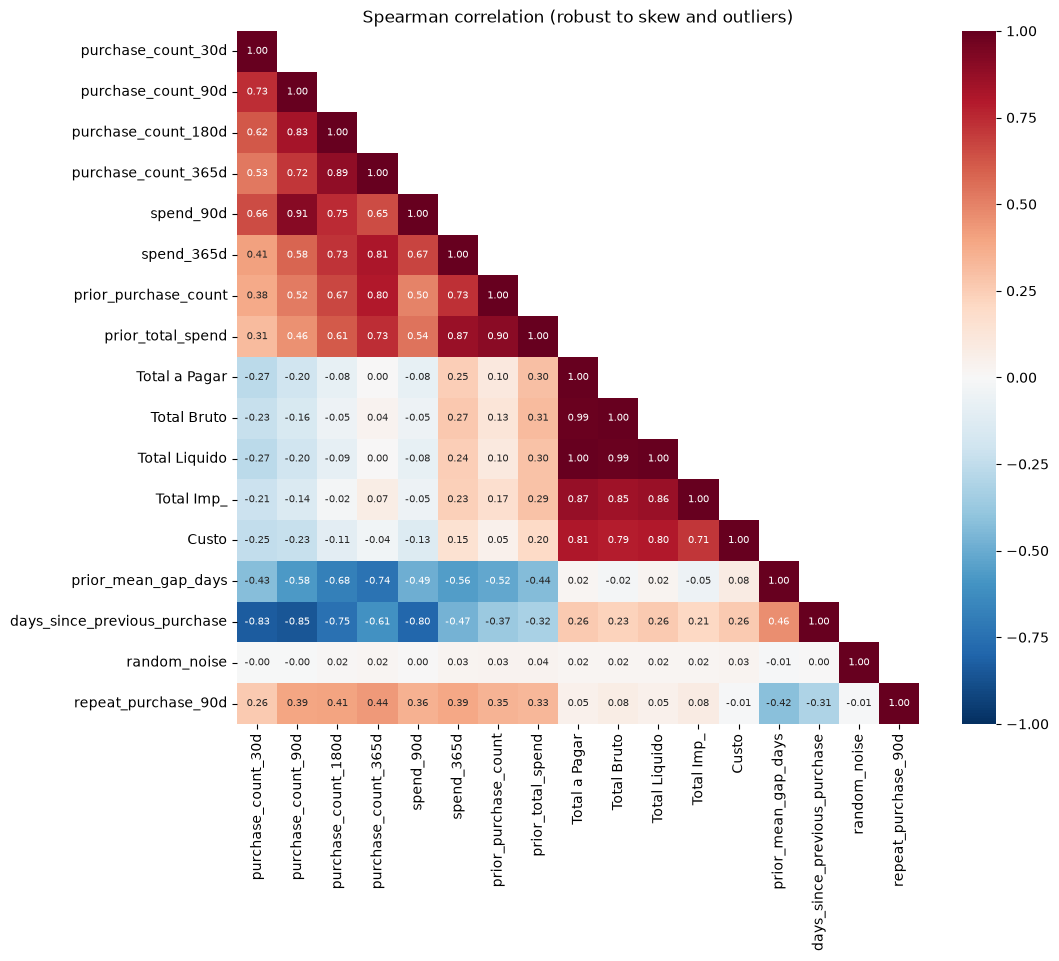

In [41]:
corr_cols = ["purchase_count_30d", "purchase_count_90d", "purchase_count_180d", "purchase_count_365d",
             "spend_90d", "spend_365d", "prior_purchase_count", "prior_total_spend",
             "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Custo",
             "prior_mean_gap_days", "days_since_previous_purchase", "random_noise", TARGET]
spearman = train[corr_cols].corr(method="spearman")

# Correlation of each variable with the target, ranked
print(spearman[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
plt.figure(figsize=(11, 9))
sns.heatmap(spearman, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation (robust to skew and outliers)")
plt.show()

**What we see:**
- Previous purchasing activity is related to repeat purchases: the purchase counts (`purchase_count_90d`, `prior_purchase_count`, …) correlate positively with the target, while `days_since_previous_purchase` and `prior_mean_gap_days` correlate negatively (longer gaps → less likely to return).
- Strong **redundancy** between predictors: `Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_` and `Custo` are almost perfectly correlated (the same amount before/after tax and discounts), and each rolling count is highly correlated with its rolling spend.
- `random_noise` has ≈0 correlation with the target and with every other variable.

### 1.12. The auxiliary `clientes.csv` table

In [42]:
print("Duplicated customer_id in clientes:", clientes["customer_id"].duplicated().sum())
print("Train customers missing from clientes:", (~train["customer_id"].isin(clientes["customer_id"])).sum())
print("Test customers missing from clientes :", (~test["customer_id"].isin(clientes["customer_id"])).sum())
print()
print(pd.DataFrame({"n_unique": clientes.nunique(),
                    "% missing": (clientes.isna().mean() * 100).round(1)}).to_string())

Duplicated customer_id in clientes: 0
Train customers missing from clientes: 0
Test customers missing from clientes : 0

                     n_unique  % missing
customer_id              1143        0.0
country_or_region          11        0.0
commercial_region          37       10.0
island                     10       50.6
municipality              183       13.9
city                      417       47.8
postal_area               271        6.2
postal_code               828       14.9
street                    511       52.3
address                  1120        0.5
customer_type               0      100.0
company_name             1141        0.0
customer_since_year        12        0.0


**What we see:**
- One row per customer, and every train/test customer is present, so the table can be joined safely through `customer_id`.
- `customer_type` is 100% missing.
- `address`, `street`, `postal_code`, `city` and `company_name` have hundreds of levels (practically one per customer), so they behave like identifiers.
- `country_or_region`, `commercial_region` and `customer_since_year` have few levels.

### 1.13. Summary of the exploratory analysis

| Topic | Finding |
|---|---|
| Target | ≈56% / 44%, reasonably balanced |
| Empty rows | 65 training rows with only `ID`, `customer_id` and target |
| Missing values | `prior_*` history columns missing mostly because the customer has 0–1 previous purchases (structural) |
| Impossible values | Negative gaps; negative or 1e9 values in `prior_mean_purchase_value` and `spend_365d` |
| Duplicates | No duplicated rows or IDs; ~610 customers with many purchases each |
| Categoricals | Consistent spelling; `transport_method` has ~80 levels; some test levels never appear in train |
| Time | Test (2025–2026) is after train (2015–2025); cumulative variables drift upward |
| Distributions | Monetary and count variables strongly right-skewed with outliers |
| Relationships | Frequency and recency are the strongest signals; `payment_type`, `salesperson` informative; current amount weak |
| Redundancy | `Total *` / `Custo` and counts/spends nearly identical |
| Identifiers / noise | `ID`, `customer_id` are identifiers; `random_noise` unrelated to everything |
| `clientes.csv` | Complete coverage; most columns identifier-like |